# 04b — Chemokine axes: receptors, source → target, and the IFN-γ / MHC / cytotoxic link

`01` mapped who makes each chemokine and `02`/`03` tested which ones respond to treatment. This
notebook asks what the responding chemokines are **connected to**:

| § | question | unit and test |
|---|---|---|
| 2 | **Receptor map** — who carries each cognate receptor, and does treatment change the receptor-positive fraction? | sample-level detection fraction (exact relabelling) + binomial GLMM `(1 | sample)` |
| 3 | **Q3: ligand ↔ receiving population** — across samples, does ligand expression in a source track the abundance of the receiving population? | treated samples, `abundance ~ ligand + car + rt + site`, Freedman–Lane permutation; and the within-mouse Tu1 − Tu2 version |
| 4 | **Q4: chemokines vs IFN-γ / MHC** in macrophage states | across samples (partial, Freedman–Lane) and within samples (cell-level ρ, summarised over samples) |
| 5 | **Q4: chemokines vs cytotoxicity** — Cxcl9/10 vs CD8/NK abundance and `Gzmb`/`Prf1`/`Nkg7` | treated samples, Freedman–Lane |
| 6 | **SPP1-high vs IFN-stimulated macrophages** — chemokine profiles, and whether the gap moves with treatment | paired within-sample DESeq2 `~ sample + state`; state-gap contrasts by exact relabelling |
| 7 | the **chemokine axis table** | |

### What these data can and cannot say
Everything here is **transcriptional**. A ligand rising in a source and a receptor-bearing
population being more abundant in the same samples is an **association with composition** — it
is consistent with recruitment but does not establish it. Directional migration, chemokine
protein, gradients and receptor signalling are not measured. The tables keep **observed
transcriptional change** and **inferred chemotactic potential** in separate columns.

**Circularity guard.** Hallmark IFN-γ contains `Cxcl9`, `Cxcl10` and `Cxcl11`. Every IFN-γ score
that is compared with a chemokine below has the chemokines **removed** first (`IFNG_noCXCL`).

## 1. Config

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools, logging
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference
logging.disable(logging.WARNING)

pd.set_option("display.width", 290); pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 500)
_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
OUT = PROJ/"results/mhc_cytotox"; FIG = OUT/"figures"
MIN_CELLS, MIN_CELLS_REC, N_FL, SEED = 10, 8, 5000, 0
rng = np.random.default_rng(SEED)

PB = pd.read_parquet(OUT/"pseudobulk_counts.parquet")
PBM = pd.read_csv(OUT/"pseudobulk_meta.csv").set_index("key").loc[PB.index]
CAT = json.load(open(OUT/"programs.json")); PROGRAMS, AXES = CAT["programs"], CAT["axes"]
L = np.log2(PB.div(PB.sum(1), axis=0) * 1e6 + 1)
cp = pd.read_parquet(OUT/"cell_panel.parquet")
design = pd.read_csv(OUT/"design_samples.csv").set_index("sample")
TREATED = design.index[design.arm != "NoTx"]
print(f"{len(TREATED)} treated samples")

CHEM = {"Cxcl11"}
IFNG_NOC = [g for g in PROGRAMS["IFNG_Hallmark"]["genes"] if g not in {"Cxcl9", "Cxcl10", "Cxcl11"}]
print(f"IFN-gamma score without chemokines: {len(IFNG_NOC)} of {len(PROGRAMS['IFNG_Hallmark']['genes'])} genes")


def lognorm(d, genes_):
    return np.log1p(d[genes_].div(d.total_counts, axis=0) * 1e4)


def lvl(group, gene):
    """log2 CPM+1 of one gene in a group's pseudobulk, per sample (>= MIN_CELLS cells)."""
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    return pd.Series(L.loc[d.index, gene].values, index=d["sample"].values)


def score(group, genes_):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    Lg = L.loc[d.index, [g for g in genes_ if g in L.columns]]
    Lg = Lg.loc[:, Lg.mean() >= 1.0]
    tr = (d.arm != "NoTx").values
    Z = (Lg - Lg[tr].mean()) / Lg[tr].std().replace(0, np.nan)
    return pd.Series(Z.mean(1).values, index=d["sample"].values)


# composition: CLR over lvl2 types, all cells (Erythrocyte excluded)
comp = pd.crosstab(cp["sample"], cp.ct2).drop(columns=["Erythrocyte"], errors="ignore")
lg_ = np.log(comp + 0.5); CLR = lg_.sub(lg_.mean(1), axis=0)

23 treated samples
IFN-gamma score without chemokines: 180 of 182 genes


## 2. Receptor map, and treatment effects on receptor-positive fractions

The XCR1 axis has no measurable receptor (`Xcr1` ~0% in every cell type, including cDC — no
cDC1 were captured), so it is carried as **ligand-only**.

In [2]:
REC_TARGETS = {"Cxcr3": ["CD8_T", "NK", "Treg"], "Ccr5": ["NK", "CD8_T", "M1_like_Mac", "Classical_Mono"],
               "Ccr2": ["Classical_Mono", "Intermediate_Mac", "NK"], "Cxcr2": ["N1_like_Neu", "N2_like_Neu"],
               "Ccr4": ["NKT", "CD4_T", "Treg"], "Cxcr6": ["CD8_T", "NKT", "CD4_T"],
               "Cxcr4": ["CD8_T", "NK", "M2_like_Mac", "Classical_Mono"], "Ackr3": ["Fibroblast", "Endothelial"],
               "Xcr1": ["cDC"]}
RF = pd.read_csv(OUT/"q1_receptor_positive_fraction.csv")
rmap = []
for rec, tg in REC_TARGETS.items():
    for t in tg:
        d = RF[(RF.ct2 == t) & (RF.n >= MIN_CELLS_REC)]
        tr = d[~d.cond.str.startswith("NoTx")]
        rmap.append(dict(receptor=rec, target=t, n_samples=len(tr), cells_median=tr.n.median(),
                         pct_pos_treated=100 * tr[rec].mean() if len(tr) else np.nan,
                         measurable=bool(len(tr) >= 8 and tr[rec].mean() >= 0.05)))
RMAP = pd.DataFrame(rmap)
print(RMAP.round(1).to_string(index=False))


def two_arm_null(v, meta, A, B, site):
    idx = [i for i in meta.index[meta.arm.isin([A, B]) & (meta.site == site)] if np.isfinite(v.get(i, np.nan))]
    obs = (meta.loc[idx, "arm"] == A).values; k, n = int(obs.sum()), len(idx)
    if k < 2 or n - k < 2: return None
    x = v.loc[idx].values
    out = [x[obs].mean() - x[~obs].mean()]
    for c in itertools.combinations(range(n), k):
        msk = np.isin(np.arange(n), c)
        if not (msk == obs).all(): out.append(x[msk].mean() - x[~msk].mean())
    return np.array(out)


def p2(a): return float((np.abs(a) >= abs(a[0]) - 1e-12).mean())


def effects(v, meta):
    """PSCA (both strata, site-matched), direct RT, indirect RT on a per-sample Series v."""
    out = {}
    nr = [n_ for s in (1, 2) if (n_ := two_arm_null(v, meta, "CyPSCA", "CyT72", s)) is not None]
    rt = [n_ for s in (1, 2) if (n_ := two_arm_null(v, meta, "RTCyPSCA", "RTCyT72", s)) is not None]
    def m2(parts): return parts[0] if len(parts) == 1 else ((parts[0][:, None] + parts[1][None, :]) / 2).ravel()
    strata = {"PSCA": (m2(nr) if nr else None, m2(rt) if rt else None),
              "direct RT": (two_arm_null(v, meta, "RTCyPSCA", "CyPSCA", 1), two_arm_null(v, meta, "RTCyT72", "CyT72", 1)),
              "indirect RT": (two_arm_null(v, meta, "RTCyPSCA", "CyPSCA", 2), two_arm_null(v, meta, "RTCyT72", "CyT72", 2))}
    for eff, (a, b) in strata.items():
        r = {}
        if a is not None: r["d_1"], r["p_1"] = a[0], p2(a)
        if b is not None: r["d_2"], r["p_2"] = b[0], p2(b)
        if a is not None and b is not None:
            mn = ((a[:, None] + b[None, :]) / 2).ravel()
            it = ((b[:, None] - a[None, :]) if eff == "PSCA" else (a[:, None] - b[None, :])).ravel()
            r.update(main=mn[0], p_main=p2(mn), inter=it[0], p_inter=p2(it), agree=bool(np.sign(a[0]) == np.sign(b[0])))
        out[eff] = r
    return out


rrow = []
meta_s = design[["arm", "site", "mouse"]]
for rec, tg in REC_TARGETS.items():
    for t in tg:
        d = RF[(RF.ct2 == t) & (RF.n >= MIN_CELLS_REC)].set_index("sample")
        if len(d) < 6: continue
        for eff, r in effects(d[rec], meta_s.loc[d.index]).items():
            rrow.append(dict(receptor=rec, target=t, effect=eff, **r))
RECX = pd.DataFrame(rrow)
RECX.to_csv(OUT/"chem_receptor_fraction_contrasts.csv", index=False)
print("\nreceptor-positive fraction, sample-level contrasts (d = difference in fraction):")
print(RECX.round(3).to_string(index=False))

# cell-level GLMM cross-check for the lymphoid receptors
gl = []
COMPS = [("PSCA nonRT Tu1", "CyPSCA", "CyT72", 1), ("PSCA nonRT Tu2", "CyPSCA", "CyT72", 2),
         ("PSCA RT Tu1", "RTCyPSCA", "RTCyT72", 1), ("PSCA RT Tu2", "RTCyPSCA", "RTCyT72", 2),
         ("direct RT PSCA", "RTCyPSCA", "CyPSCA", 1), ("direct RT TAG72", "RTCyT72", "CyT72", 1),
         ("indirect RT PSCA", "RTCyPSCA", "CyPSCA", 2), ("indirect RT TAG72", "RTCyT72", "CyT72", 2)]
for rec, t in [("Cxcr3", "CD8_T"), ("Cxcr6", "CD8_T"), ("Ccr5", "NK"), ("Ccr5", "CD8_T"), ("Ccr2", "NK"),
               ("Cxcr3", "NK"), ("Cxcr4", "CD8_T"), ("Ccr2", "Classical_Mono"), ("Cxcr2", "N1_like_Neu")]:
    C_ = cp[cp.ct2 == t]
    for name, A, B, site in COMPS:
        d = C_[C_.arm.isin([A, B]) & (C_.site == site)].copy()
        if d["sample"].nunique() < 4 or d.groupby("arm")["sample"].nunique().min() < 2: continue
        if len(d) > 4000: d = d.groupby("sample", group_keys=False).apply(lambda x: x.sample(min(len(x), 400), random_state=0))
        d["x"] = (d.arm == A).astype(float); d["y"] = (d[rec] > 0).astype(float)
        if d.y.sum() < 5 or (1 - d.y).sum() < 5: continue
        try:
            m = BinomialBayesMixedGLM.from_formula("y ~ x", {"sample": "0 + C(sample)"}, d).fit_vb()
            b, s = float(m.fe_mean[1]), float(m.fe_sd[1])
            gl.append(dict(receptor=rec, target=t, comparison=name, n_cells=len(d), logodds=b, z=b / s,
                           p=2 * (1 - stats.norm.cdf(abs(b / s)))))
        except Exception as e:
            gl.append(dict(receptor=rec, target=t, comparison=name, error=str(e)[:60]))
GLR = pd.DataFrame(gl)
GLR.to_csv(OUT/"chem_receptor_glmm.csv", index=False)
print("\nreceptor-positive GLMM z (|z| > 2 is the cross-check threshold):")
print(GLR.pivot_table(index=["receptor", "target"], columns="comparison", values="z").round(1).to_string())

receptor           target  n_samples  cells_median  pct_pos_treated  measurable
   Cxcr3            CD8_T         17          21.0             27.3        True
   Cxcr3               NK         22          39.0              5.8        True
   Cxcr3             Treg          0           NaN              NaN       False
    Ccr5               NK         22          39.0             83.6        True
    Ccr5            CD8_T         17          21.0             56.2        True
    Ccr5      M1_like_Mac         23         621.0             93.4        True
    Ccr5   Classical_Mono         23        1118.0             86.4        True
    Ccr2   Classical_Mono         23        1118.0             84.3        True
    Ccr2 Intermediate_Mac         23         389.0             90.8        True
    Ccr2               NK         22          39.0             83.9        True
   Cxcr2      N1_like_Neu         22          44.0             56.0        True
   Cxcr2      N2_like_Neu         21    


receptor-positive GLMM z (|z| > 2 is the cross-check threshold):
comparison               PSCA RT Tu1  PSCA RT Tu2  PSCA nonRT Tu1  PSCA nonRT Tu2  direct RT PSCA  direct RT TAG72  indirect RT PSCA  indirect RT TAG72
receptor target                                                                                                                                        
Ccr2     Classical_Mono         -9.8         -1.7           -14.6           -10.0             0.3             -2.8               3.8               -6.3
         NK                     -3.7          1.7            -5.0            -1.3             0.4             -1.4               1.7               -2.3
Ccr5     CD8_T                  -0.8          1.3            -5.1            -2.7             5.3              1.8               2.9               -1.9
         NK                     -1.8          1.6             0.0             1.8            -2.6             -0.6              -0.7                0.1
Cxcr2    N1_like_Neu  

## 3. Q3 — Does ligand expression in a source track the abundance of the receiving population?

Treated samples only. For each (ligand, source, target):

`abundance(target) ~ ligand(source) + car + rt + site`

* `abundance` is the target's **CLR** over all lvl2 types (so a myeloid influx does not
  mechanically deflate every lymphoid fraction), and separately the **log-odds of
  receptor-positive target cells** among all cells;
* `ligand` is log2 CPM in the source's pseudobulk — **per-cell expression**, so the source's own
  abundance does not enter;
* p-values come from a **Freedman–Lane permutation** (residuals of the covariate-only model are
  permuted, the full model refitted), because 23 samples with four covariates is too few for
  asymptotic t tests. BH across every pair.

Then the **within-mouse** version: Tu1 − Tu2 differences across mice (both tumours share the
animal, so animal-level confounders cancel), permuting Δligand within arm.

The **minimum detectable partial correlation** at this n is printed with the table — anything
smaller is invisible here, whatever the biology.

In [3]:
PAIRS = [   # axis, ligand, sources, targets
    ("CXCR3", "Cxcl9", ["IFN_stimulated_Mac", "Classical_Mono", "M2_like_Mac", "cDC"], ["CD8_T", "NK", "Treg"]),
    ("CXCR3", "Cxcl10", ["IFN_stimulated_Mac", "Classical_Mono", "M2_like_Mac"], ["CD8_T", "NK", "Treg"]),
    ("CCR5", "Ccl3", ["Classical_Mono", "M2_like_Mac", "N2_like_Neu"], ["NK", "CD8_T"]),
    ("CCR5", "Ccl4", ["Classical_Mono", "IFN_stimulated_Mac", "M2_like_Mac"], ["NK", "CD8_T"]),
    ("CCR5", "Ccl5", ["IFN_stimulated_Mac", "cDC", "Classical_Mono"], ["NK", "CD8_T"]),
    ("CCR2", "Ccl2", ["M2_like_Mac", "Classical_Mono"], ["Classical_Mono", "Intermediate_Mac"]),
    ("CCR2", "Ccl7", ["M2_like_Mac", "Classical_Mono"], ["Classical_Mono", "Intermediate_Mac"]),
    ("CCR2", "Ccl12", ["M2_like_Mac", "Classical_Mono"], ["Classical_Mono", "Intermediate_Mac"]),
    ("CXCR2", "Cxcl1", ["M2_like_Mac", "Classical_Mono"], ["N1_like_Neu", "N2_like_Neu"]),
    ("CXCR2", "Cxcl2", ["M2_like_Mac", "Classical_Mono", "N2_like_Neu"], ["N1_like_Neu", "N2_like_Neu"]),
    ("CXCR2", "Cxcl3", ["M2_like_Mac", "N2_like_Neu"], ["N1_like_Neu", "N2_like_Neu"]),
    ("CCR4", "Ccl17", ["cDC", "Intermediate_Mac"], ["Treg", "CD4_T", "NKT"]),
    ("CCR4", "Ccl22", ["cDC"], ["Treg", "CD4_T", "NKT"]),
    ("CXCR6", "Cxcl16", ["M2_like_Mac", "IFN_stimulated_Mac", "cDC"], ["CD8_T", "NKT", "CD4_T"]),
    ("CXCR4", "Cxcl12", ["Fibroblast", "Endothelial"], ["CD8_T", "NK"]),
    ("XCR1", "Xcl1", ["NK", "CD8_T"], ["cDC"]),
]
RECEPTOR_OF = {"CXCR3": "Cxcr3", "CCR5": "Ccr5", "CCR2": "Ccr2", "CXCR2": "Cxcr2", "CCR4": "Ccr4",
               "CXCR6": "Cxcr6", "CXCR4": "Cxcr4", "XCR1": "Xcr1"}


def freedman_lane(y, x, Zc, n_perm=N_FL, seed=SEED):
    """t of x in y ~ x + Zc, Freedman-Lane permutation p. Returns (beta_std, partial_r, t, p, n)."""
    g_ = np.random.default_rng(seed)
    ok = np.isfinite(y) & np.isfinite(x) & np.isfinite(Zc).all(1)
    y, x, Zc = y[ok], x[ok], Zc[ok]
    n = len(y)
    if n < Zc.shape[1] + 4 or np.std(x) == 0: return (np.nan,) * 4 + (n,)
    Xf = np.column_stack([np.ones(n), x, Zc]); Xr = np.column_stack([np.ones(n), Zc])
    def tstat(yy):
        b, *_ = np.linalg.lstsq(Xf, yy, rcond=None); res = yy - Xf @ b
        s2 = res @ res / (n - Xf.shape[1]); cov = s2 * np.linalg.pinv(Xf.T @ Xf)
        return b[1] / np.sqrt(cov[1, 1])
    t0 = tstat(y)
    br, *_ = np.linalg.lstsq(Xr, y, rcond=None); fit_r = Xr @ br; e = y - fit_r
    null = np.array([tstat(fit_r + g_.permutation(e)) for _ in range(n_perm)])
    p = (1 + (np.abs(null) >= abs(t0)).sum()) / (1 + n_perm)
    df = n - Xf.shape[1]; pr = t0 / np.sqrt(t0 ** 2 + df)
    return t0 * np.std(y) / max(np.std(x), 1e-12) / np.sqrt(n) , pr, t0, p, n


def covars(samples):
    d = design.loc[samples]
    return np.column_stack([(d.cart == "PSCA").astype(float), d.RT.astype(float), (d.site == 1).astype(float)])


def rec_pos_logodds(target, rec):
    d = cp[cp.ct2 == target]
    k = d.groupby("sample")[rec].apply(lambda v: (v > 0).sum()).reindex(comp.index).fillna(0)
    N = comp.sum(1)
    return np.log((k + 0.5) / (N - k + 0.5))


rows = []
for axis, lig, sources, targets in PAIRS:
    rec = RECEPTOR_OF[axis]
    for src in sources:
        x_all = lvl(src, lig)
        for tgt in targets:
            for kind, yser in [("CLR", CLR[tgt] if tgt in CLR else None),
                               ("receptor+ log-odds", rec_pos_logodds(tgt, rec) if rec in cp else None)]:
                if yser is None: continue
                smp = [s for s in TREATED if s in x_all.index]
                x, y = x_all.loc[smp].values, yser.reindex(smp).values
                if np.nanmean(x) < 1.0: continue                        # ligand barely expressed in source
                b, pr, t, p, n = freedman_lane(y, x, covars(smp))
                rows.append(dict(axis=axis, ligand=lig, source=src, target=tgt, abundance=kind, n=n,
                                 partial_r=pr, t=t, p_FL=p))
ASSOC = pd.DataFrame(rows)
ASSOC["q_BH"] = multipletests(ASSOC.p_FL.fillna(1), method="fdr_bh")[1]
n_ = int(ASSOC.n.median())
r_mde = np.tanh((stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) / np.sqrt(n_ - 3 - 3))
print(f"{len(ASSOC)} ligand-source-target tests, median n = {n_} treated samples; minimum detectable "
      f"|partial r| (80% power) ~ {r_mde:.2f}")
print(ASSOC.sort_values("p_FL").head(25).round(3).to_string(index=False))

# within-mouse: Tu1 - Tu2 differences, permute delta-ligand within arm
mw = []
for axis, lig, sources, targets in PAIRS:
    for src in sources:
        x_all = lvl(src, lig)
        for tgt in targets:
            if tgt not in CLR: continue
            dd = design.loc[TREATED].assign(x=x_all.reindex(TREATED).values, y=CLR[tgt].reindex(TREATED).values)
            w = dd.pivot_table(index=["mouse", "arm"], columns="site", values=["x", "y"]).dropna()
            if len(w) < 6: continue
            dx = (w["x"][1] - w["x"][2]).values; dy = (w["y"][1] - w["y"][2]).values
            arms = w.index.get_level_values("arm").values
            r0 = stats.pearsonr(dx, dy)[0] if np.std(dx) > 0 and np.std(dy) > 0 else np.nan
            null = []
            for _ in range(2000):
                dxp = dx.copy()
                for a in np.unique(arms):
                    m = arms == a; dxp[m] = rng.permutation(dxp[m])
                null.append(stats.pearsonr(dxp, dy)[0] if np.std(dxp) > 0 else 0)
            mw.append(dict(axis=axis, ligand=lig, source=src, target=tgt, n_mice=len(dx), r_within_mouse=r0,
                           p_perm=float((np.abs(null) >= abs(r0)).mean()) if np.isfinite(r0) else np.nan))
MW = pd.DataFrame(mw)
ASSOC = ASSOC.merge(MW, on=["axis", "ligand", "source", "target"], how="left")
ASSOC.to_csv(OUT/"chem_ligand_population_association.csv", index=False)
print("\nwithin-mouse (Tu1 - Tu2) correlations, p_perm < 0.10:")
print(MW[MW.p_perm < 0.10].round(3).to_string(index=False) if len(MW) else "none")

178 ligand-source-target tests, median n = 23 treated samples; minimum detectable |partial r| (80% power) ~ 0.59
 axis ligand             source           target          abundance  n  partial_r      t  p_FL  q_BH
CXCR2  Cxcl2        M2_like_Mac      N2_like_Neu receptor+ log-odds 23      0.749  4.801 0.000 0.012
CXCR2  Cxcl2     Classical_Mono      N2_like_Neu receptor+ log-odds 23      0.756  4.905 0.000 0.012
CXCR2  Cxcl2     Classical_Mono      N1_like_Neu receptor+ log-odds 23      0.826  6.219 0.000 0.012
CXCR2  Cxcl1     Classical_Mono      N1_like_Neu receptor+ log-odds 23      0.679  3.924 0.000 0.012
CXCR2  Cxcl2        M2_like_Mac      N1_like_Neu receptor+ log-odds 23      0.840  6.576 0.000 0.012
CXCR2  Cxcl1     Classical_Mono      N2_like_Neu receptor+ log-odds 23      0.724  4.458 0.000 0.012
CXCR2  Cxcl2        M2_like_Mac      N1_like_Neu                CLR 23      0.742  4.698 0.001 0.015
CXCR2  Cxcl1        M2_like_Mac      N2_like_Neu receptor+ log-odds 23      0.7


within-mouse (Tu1 - Tu2) correlations, p_perm < 0.10:
 axis ligand             source      target  n_mice  r_within_mouse  p_perm
CXCR3  Cxcl9 IFN_stimulated_Mac          NK      11          -0.398   0.036
CXCR3  Cxcl9                cDC        Treg      11           0.274   0.068
 CCR5   Ccl4 IFN_stimulated_Mac          NK      11          -0.634   0.069
 CCR5   Ccl4        M2_like_Mac          NK      11          -0.718   0.094
 CCR5   Ccl5 IFN_stimulated_Mac          NK      11          -0.610   0.008
CXCR2  Cxcl1        M2_like_Mac N1_like_Neu      11           0.763   0.096
CXCR2  Cxcl2        M2_like_Mac N1_like_Neu      11           0.882   0.036
CXCR2  Cxcl2     Classical_Mono N1_like_Neu      11           0.893   0.038
 CCR4  Ccl17                cDC        Treg      11          -0.440   0.046
 CCR4  Ccl17   Intermediate_Mac       CD4_T      11           0.606   0.006
 XCR1   Xcl1                 NK         cDC       8           0.725   0.085


## 4. Q4 — Do macrophages with more IFN-γ signalling and MHC also make more Cxcl9 / Cxcl10?

**(a) Across samples**, inside each myeloid state: IFN-γ (chemokines removed), MHC-I and MHC-II
scores vs Cxcl9 / Cxcl10, with car / rt / site partialled out (Freedman–Lane).

**(b) Within samples**, cell by cell: Spearman ρ between a cell's IFN-γ / MHC score and its
Cxcl9 / Cxcl10, per sample (>= 30 cells of the state), then the mean ρ across samples
(one-sample t over samples — the sample is the unit, the cells only make each sample's ρ).

In [4]:
STATES = ["IFN_stimulated_Mac", "Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Mmp12_high_Mac",
          "SPP1_TAM", "Classical_Mono", "cDC"]
SCORES = {"IFNG_noCXCL": IFNG_NOC, "MHC_I": PROGRAMS["MHC_I_machinery"]["genes"],
          "MHC_II": PROGRAMS["MHC_II_core"]["genes"]}
a_rows = []
for st in STATES:
    for sname, gl in SCORES.items():
        s_ = score(st, gl)
        for ch in ["Cxcl9", "Cxcl10"]:
            c_ = lvl(st, ch)
            smp = [s for s in TREATED if s in s_.index and s in c_.index]
            b, pr, t, p, n = freedman_lane(c_.loc[smp].values, s_.loc[smp].values, covars(smp))
            a_rows.append(dict(state=st, score=sname, chemokine=ch, n=n, partial_r=pr, p_FL=p,
                               r_raw=stats.pearsonr(s_.loc[smp], c_.loc[smp])[0]))
ACROSS = pd.DataFrame(a_rows)
ACROSS["q_BH"] = multipletests(ACROSS.p_FL.fillna(1), method="fdr_bh")[1]

cell_state = {"IFN_stimulated_Mac": cp.ct3 == "IFN_stimulated_Mac", "Apoe_high_Mac": cp.ct3 == "Apoe_high_Mac",
              "Arg1_high_Mac": cp.ct3 == "Arg1_high_Mac", "Fn1_high_Mac": cp.ct3 == "Fn1_high_Mac",
              "Mmp12_high_Mac": cp.ct3 == "Mmp12_high_Mac", "SPP1_TAM": cp.SPP1_TAM,
              "Classical_Mono": cp.ct2 == "Classical_Mono", "cDC": cp.ct2 == "cDC"}
w_rows = []
for st, m in cell_state.items():
    d = cp[m.values]
    sc = {k: lognorm(d, [g for g in gl if g in d]).mean(1) for k, gl in SCORES.items()}
    ch = lognorm(d, ["Cxcl9", "Cxcl10"])
    for s, idx in d.groupby("sample").groups.items():
        if len(idx) < 30: continue
        for k in SCORES:
            for c in ["Cxcl9", "Cxcl10"]:
                a_, b_ = sc[k].loc[idx], ch[c].loc[idx]
                if a_.std() > 0 and b_.std() > 0:
                    w_rows.append(dict(state=st, sample=s, score=k, chemokine=c,
                                       rho=stats.spearmanr(a_, b_).statistic))
WR = pd.DataFrame(w_rows)
WITHIN = (WR.groupby(["state", "score", "chemokine"]).rho
            .agg(n_samples="size", mean_rho="mean", frac_pos=lambda v: (v > 0).mean(),
                 p_t=lambda v: stats.ttest_1samp(v, 0).pvalue).reset_index())
Q4 = ACROSS.merge(WITHIN, on=["state", "score", "chemokine"], how="outer")
Q4.to_csv(OUT/"chem_ifn_mhc_link.csv", index=False)
print(Q4.round(3).to_string(index=False))

             state       score chemokine  n  partial_r  p_FL  r_raw  q_BH  n_samples  mean_rho  frac_pos   p_t
     Apoe_high_Mac IFNG_noCXCL    Cxcl10 23      0.410 0.066  0.604 0.123         28     0.473     0.964 0.000
     Apoe_high_Mac IFNG_noCXCL     Cxcl9 23      0.406 0.069  0.763 0.123         26     0.263     1.000 0.000
     Apoe_high_Mac       MHC_I    Cxcl10 23      0.501 0.028  0.621 0.078         28     0.272     0.964 0.000
     Apoe_high_Mac       MHC_I     Cxcl9 23      0.734 0.000  0.898 0.006         26     0.267     1.000 0.000
     Apoe_high_Mac      MHC_II    Cxcl10 23      0.284 0.223  0.548 0.297         28     0.093     0.857 0.000
     Apoe_high_Mac      MHC_II     Cxcl9 23      0.560 0.009  0.849 0.035         26     0.210     0.962 0.000
     Arg1_high_Mac IFNG_noCXCL    Cxcl10 23      0.136 0.559  0.637 0.639         27     0.304     0.963 0.000
     Arg1_high_Mac IFNG_noCXCL     Cxcl9 23      0.448 0.045  0.726 0.097         27     0.204     1.000 0.000
 

### 4c. Do treatment effects on IFN-γ / MHC and on Cxcl9 / Cxcl10 move together?

Per (myeloid group × contrast) from `02`/`03`: the program-score effect on IFN-γ / MHC against
the DESeq2 log2FC of Cxcl9 / Cxcl10. Points are not independent (shared samples across
contrasts), so this is descriptive — the sample-level tests above carry the inference.

In [5]:
DE = pd.read_parquet(OUT/"de_all.parquet")
PT = pd.read_csv(OUT/"program_score_contrasts.csv") if (OUT/"program_score_contrasts.csv").exists() else None
MAP = {"PSCA": [("PSCA_nonRT", "d_nonRT"), ("PSCA_RT", "d_RT")],
       "direct RT": [("directRT_PSCA", "d_PSCA"), ("directRT_TAG72", "d_TAG72")],
       "indirect RT": [("indirectRT_PSCA", "d_PSCA"), ("indirectRT_TAG72", "d_TAG72")]}
cm = []
if PT is not None:
    for g_ in ["IFN_stimulated_Mac", "M2_like_Mac", "Classical_Mono", "SPP1_TAM", "Intermediate_Mac", "cDC"]:
        for eff, lst in MAP.items():
            for cname, dcol in lst:
                for prog in ["IFNG_Hallmark", "MHC_I_machinery", "MHC_II_core"]:
                    t = PT[(PT.group == g_) & (PT.effect == eff) & (PT.program == prog)]
                    for ch in ["Cxcl9", "Cxcl10"]:
                        de = DE[(DE.group == g_) & (DE.contrast == cname) & (DE.gene == ch)]
                        if len(t) and len(de) and dcol in t:
                            cm.append(dict(group=g_, contrast=cname, program=prog, chemokine=ch,
                                           program_effect=t[dcol].iloc[0], chem_lfc=de.log2FoldChange.iloc[0],
                                           chem_padj=de.padj.iloc[0]))
CM = pd.DataFrame(cm)
CM.to_csv(OUT/"chem_ifn_comovement.csv", index=False)
if len(CM):
    for (prog, ch), d in CM.groupby(["program", "chemokine"]):
        d = d.dropna(subset=["program_effect", "chem_lfc"])
        r = stats.spearmanr(d.program_effect, d.chem_lfc).statistic if len(d) > 4 else np.nan
        print(f"    {prog:<16s} effect vs {ch:<6s} log2FC: Spearman {r:+.2f} over {len(d)} group x contrast points")

    IFNG_Hallmark    effect vs Cxcl10 log2FC: Spearman +0.73 over 36 group x contrast points
    IFNG_Hallmark    effect vs Cxcl9  log2FC: Spearman +0.74 over 36 group x contrast points
    MHC_II_core      effect vs Cxcl10 log2FC: Spearman +0.43 over 36 group x contrast points
    MHC_II_core      effect vs Cxcl9  log2FC: Spearman +0.47 over 36 group x contrast points
    MHC_I_machinery  effect vs Cxcl10 log2FC: Spearman +0.67 over 36 group x contrast points
    MHC_I_machinery  effect vs Cxcl9  log2FC: Spearman +0.75 over 36 group x contrast points


## 5. Q4 — Are Cxcl9 / Cxcl10 associated with cytotoxic lymphocytes and their effector program?

Treated samples, `outcome ~ chemokine + car + rt + site`, Freedman–Lane. Outcomes: CLR of CD8_T,
NK and NKT; and in the pooled `cytotoxic_lymph` and `NK` pseudobulks, `Gzmb`, `Prf1`, `Nkg7` and
the effector module **with and without Ccl5**. The pooled lymphocyte pseudobulk is part NK and
part CD8, so its NK share is added as a covariate for the lymphocyte-expression outcomes.

In [6]:
OUTC = {}
for t in ["CD8_T", "NK", "NKT"]: OUTC[f"CLR {t}"] = CLR[t]
for grp in ["cytotoxic_lymph", "NK"]:
    for g in ["Gzmb", "Prf1", "Nkg7"]: OUTC[f"{g} in {grp}"] = lvl(grp, g)
    OUTC[f"effector in {grp}"] = score(grp, PROGRAMS["cyto_effector"]["genes"])
    OUTC[f"effector_noCcl5 in {grp}"] = score(grp, PROGRAMS["cyto_effector_noCcl5"]["genes"])
nk_share = (comp["NK"] / comp[["CD8_T", "NK", "NKT"]].sum(1)).rename("nk_share")
PRED = {"Cxcl9 IFN_stimulated_Mac": lvl("IFN_stimulated_Mac", "Cxcl9"),
        "Cxcl9 Classical_Mono": lvl("Classical_Mono", "Cxcl9"),
        "Cxcl10 Classical_Mono": lvl("Classical_Mono", "Cxcl10"),
        "Cxcl9 M2_like_Mac": lvl("M2_like_Mac", "Cxcl9"),
        "CXCR3 ligands IFN_stimulated_Mac": score("IFN_stimulated_Mac", ["Cxcl9", "Cxcl10"])}
c_rows = []
for pn, x_all in PRED.items():
    for on, y_all in OUTC.items():
        smp = [s for s in TREATED if s in x_all.index and s in y_all.index]
        Zc = covars(smp)
        if "cytotoxic_lymph" in on: Zc = np.column_stack([Zc, nk_share.reindex(smp).values])
        b, pr, t, p, n = freedman_lane(y_all.loc[smp].values, x_all.loc[smp].values, Zc)
        c_rows.append(dict(predictor=pn, outcome=on, n=n, partial_r=pr, p_FL=p))
CYT = pd.DataFrame(c_rows)
CYT["q_BH"] = multipletests(CYT.p_FL.fillna(1), method="fdr_bh")[1]
CYT.to_csv(OUT/"chem_cytotoxic_link.csv", index=False)
print(CYT.pivot_table(index="outcome", columns="predictor", values="partial_r").round(2).to_string())
print("\np_FL < 0.05:")
print(CYT[CYT.p_FL < 0.05].round(3).to_string(index=False) or "none")

predictor                           CXCR3 ligands IFN_stimulated_Mac  Cxcl10 Classical_Mono  Cxcl9 Classical_Mono  Cxcl9 IFN_stimulated_Mac  Cxcl9 M2_like_Mac
outcome                                                                                                                                                       
CLR CD8_T                                                      -0.35                  -0.33                  0.19                      0.07              -0.05
CLR NK                                                         -0.17                  -0.32                 -0.10                      0.08               0.20
CLR NKT                                                        -0.07                  -0.13                  0.01                      0.24               0.03
Gzmb in NK                                                      0.03                   0.16                  0.35                     -0.06               0.08
Gzmb in cytotoxic_lymph                       

## 6. SPP1-high vs IFN-stimulated macrophages — chemokine profiles

Mutually exclusive pseudobulks from the same samples, compared with **sample as a block**
(`~ sample + state`), so mouse, site and treatment cancel. Two SPP1 definitions:

* **signature** — SPP1-TAM signature top quartile, minus IFN-stimulated cells vs
  IFN_stimulated_Mac minus SPP1-TAM;
* **Alice** — `Spp1_pos_mac` minus IFN-stimulated vs IFN_stimulated_Mac that are `Spp1_neg_mac`;

plus SPP1-TAM vs **all other macrophages** (`mac_all − SPP1_TAM`, by count subtraction).
Within-panel BH on chemokine ligands and receptors separately.

In [7]:
INF = DefaultInference(n_cpus=8)
CH_L = sorted({g for v in AXES.values() for g in v["ligands"]})
CH_R = sorted({g for v in AXES.values() for g in v["receptors"]})
EXTRA = ["Stat1", "Irf1", "Gbp2", "H2-Ab1", "Cd74", "H2-K1", "B2m", "Spp1", "Cd44"]


def pb(group):
    d = PBM[PBM.group == group]
    return PB.loc[d.index].set_axis(d["sample"].values), d.set_index("sample").n_cells


def paired_de(ga, gb, label):
    A, na = pb(ga) if isinstance(ga, str) else ga
    B, nb = pb(gb) if isinstance(gb, str) else gb
    smp = [s for s in A.index if s in B.index and na.get(s, 0) >= MIN_CELLS and nb.get(s, 0) >= MIN_CELLS]
    X = pd.concat([A.loc[smp].set_axis([f"{s}|A" for s in smp]), B.loc[smp].set_axis([f"{s}|B" for s in smp])])
    meta = pd.DataFrame({"sample": [s for s in smp] * 2,
                         "state": pd.Categorical(["A"] * len(smp) + ["B"] * len(smp), ["B", "A"])}, index=X.index)
    keep = (((X > 0).sum(0) >= 6) & (X.sum(0) >= 10 * len(X))) | X.columns.isin(CH_L + CH_R + EXTRA)
    X = X.loc[:, keep & ((X > 0).sum(0) >= 2)]
    dds = DeseqDataSet(counts=X, metadata=meta, design="~ sample + state", inference=INF, quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["state", "A", "B"], inference=INF, quiet=True); st.summary()
    r = st.results_df.assign(comparison=label, n_samples=len(smp))
    return r, smp


ma, na_ = pb("mac_all"); sa, ns_ = pb("SPP1_TAM")
other = (ma.loc[sa.index] - sa).clip(lower=0); n_other = (na_.loc[sa.index] - ns_)
COMPS6 = [("SPP1TAM_notIFN", "IFNmac_notSPP1", "SPP1-TAM (signature) vs IFN-stimulated"),
          ("SPP1alice_notIFN", "IFNmac_SPP1neg_alice", "Spp1_pos_mac (Alice) vs IFN-stimulated Spp1_neg"),
          ("SPP1_TAM", (other, n_other), "SPP1-TAM (signature) vs all other macrophages")]
sres, SMPS = [], {}
for ga, gb, lab in COMPS6:
    r, smp = paired_de(ga, gb, lab); sres.append(r.reset_index(names="gene")); SMPS[lab] = smp
SDE = pd.concat(sres, ignore_index=True)
SDE["panel"] = np.where(SDE.gene.isin(CH_L), "ligand", np.where(SDE.gene.isin(CH_R), "receptor", "other"))
SDE["panel_padj"] = np.nan
for (c_, pn), d in SDE[SDE.panel != "other"].groupby(["comparison", "panel"]):
    ok = d.pvalue.notna(); SDE.loc[d.index[ok], "panel_padj"] = multipletests(d.pvalue[ok], method="fdr_bh")[1]
SDE.to_csv(OUT/"chem_spp1_vs_ifn_mac_de.csv", index=False)
show = SDE[SDE.gene.isin(CH_L + CH_R + EXTRA)].pivot_table(index="gene", columns="comparison",
                                                           values="log2FoldChange")
q = SDE[SDE.gene.isin(CH_L + CH_R)].pivot_table(index="gene", columns="comparison", values="panel_padj")
print("log2FC, SPP1-high state over the comparator (positive = higher in SPP1-high macrophages):")
print(show.round(2).to_string())
print("\nwithin-panel BH q:")
print(q.round(4).to_string())

log2FC, SPP1-high state over the comparator (positive = higher in SPP1-high macrophages):
comparison  SPP1-TAM (signature) vs IFN-stimulated  SPP1-TAM (signature) vs all other macrophages  Spp1_pos_mac (Alice) vs IFN-stimulated Spp1_neg
gene                                                                                                                                              
Ackr3                                         3.79                                          -0.32                                             4.54
B2m                                           0.23                                           0.32                                             0.07
Ccl12                                         2.96                                           2.82                                             2.27
Ccl17                                        -4.92                                          -7.06                                             1.03
Ccl2                        

### 6b. Does the SPP1-vs-IFN chemokine gap itself move with PSCA or RT?

Per sample: log2 CPM in the SPP1-TAM pseudobulk minus the IFN-stimulated pseudobulk, then the
same sample-level contrasts as everywhere else.

In [8]:
A_, nA = pb("SPP1TAM_notIFN"); B_, nB = pb("IFNmac_notSPP1")
smp = [s for s in A_.index if s in B_.index and nA[s] >= MIN_CELLS and nB[s] >= MIN_CELLS]
LA = np.log2(A_.loc[smp].div(A_.loc[smp].sum(1), axis=0) * 1e6 + 1)
LB = np.log2(B_.loc[smp].div(B_.loc[smp].sum(1), axis=0) * 1e6 + 1)
GAP = (LA - LB)[[g for g in CH_L + CH_R if g in LA]]
gx = []
for g in GAP.columns:
    if (LA[g].mean() + LB[g].mean()) / 2 < 1.0: continue
    for eff, r in effects(GAP[g], meta_s.loc[smp]).items():
        gx.append(dict(gene=g, effect=eff, **r))
GAPX = pd.DataFrame(gx)
GAPX.to_csv(OUT/"chem_spp1_ifn_gap_contrasts.csv", index=False)
print(GAPX[(GAPX.p_main < 0.10) | (GAPX.p_inter < 0.10)].round(3).to_string(index=False)
      if "p_main" in GAPX else GAPX.head())

  gene      effect    d_1   p_1    d_2  p_2   main  p_main  inter  p_inter  agree
 Ccl12        PSCA -0.331 0.520 -0.821 0.02 -0.576   0.049 -0.490    0.421   True
 Ccl17        PSCA  1.178 0.160  1.272 0.15  1.225   0.033  0.094    0.938   True
  Ccl2        PSCA -0.463 0.175 -0.380 0.14 -0.422   0.033  0.083    0.851   True
  Ccl4   direct RT  0.612 0.100  0.379 0.40  0.496   0.070  0.233    0.705   True
  Ccl4 indirect RT  0.495 0.200 -0.322 0.30  0.086   0.695  0.817    0.035  False
  Ccl7 indirect RT  0.660 0.300  0.568 0.10  0.614   0.025  0.091    0.890   True
 Cxcl1   direct RT -1.112 0.100 -0.198 0.80 -0.655   0.070 -0.914    0.195   True
Cxcl10        PSCA  0.658 0.130  0.402 0.14  0.530   0.032 -0.256    0.623   True
 Cxcl3        PSCA  1.748 0.055  1.483 0.08  1.615   0.005 -0.264    0.841   True
 Cxcl9        PSCA -0.999 0.190 -0.708 0.08 -0.853   0.034  0.291    0.758   True
  Ppbp indirect RT  2.503 0.200  1.083 0.20  1.793   0.030  1.420    0.665   True
 Ackr3        PS

## 7. The chemokine axis table (single-cell evidence; `06` adds spatial transferability)

In [9]:
REPL = pd.read_csv(OUT/"de_panel_replication.csv")
PANEL = pd.read_csv(OUT/"de_panel_genes.csv")
rows = []
for axis, lig, sources, targets in PAIRS:
    rec = RECEPTOR_OF[axis]
    for src in sources:
        for tgt in targets:
            for eff in ["PSCA", "direct RT", "indirect RT"]:
                L_ = REPL[(REPL.gene == lig) & (REPL.group == src) & (REPL.effect == eff)]
                R_ = RECX[(RECX.receptor == rec) & (RECX.target == tgt) & (RECX.effect == eff)]
                A_ = ASSOC[(ASSOC.ligand == lig) & (ASSOC.source == src) & (ASSOC.target == tgt)
                           & (ASSOC.abundance == "CLR")]
                inter = PANEL[(PANEL.gene == lig) & (PANEL.group == src) & (PANEL.contrast == "CARxRT")]
                q4 = Q4[(Q4.state == src) & (Q4.chemokine == lig) & (Q4.score == "IFNG_noCXCL")] \
                    if lig in ("Cxcl9", "Cxcl10") else pd.DataFrame()
                cy = CYT[CYT.predictor.str.startswith(f"{lig} {src}")] if lig in ("Cxcl9", "Cxcl10") else pd.DataFrame()
                rm = RMAP[(RMAP.receptor == rec) & (RMAP.target == tgt)]
                rows.append(dict(
                    axis=axis, priority=AXES[axis]["priority"], ligand=lig, source=src, receptor=rec, target=tgt,
                    effect=eff,
                    ligand_lfc=f"{L_.lfc_1.iloc[0]:+.2f}/{L_.lfc_2.iloc[0]:+.2f}" if len(L_) else "",
                    ligand_replicated=bool(L_.replicated.iloc[0]) if len(L_) else False,
                    ligand_best_q=float(L_[["q_1", "q_2"]].min(1).iloc[0]) if len(L_) else np.nan,
                    ligand_CARxRT_lfc=float(inter.log2FoldChange.iloc[0]) if len(inter) else np.nan,
                    ligand_CARxRT_q=float(inter.panel_padj.iloc[0]) if len(inter) else np.nan,
                    receptor_pct_pos=float(rm.pct_pos_treated.iloc[0]) if len(rm) else np.nan,
                    receptor_measurable=bool(rm.measurable.iloc[0]) if len(rm) else False,
                    receptor_frac_change=float(R_["main"].iloc[0]) if len(R_) and "main" in R_ and pd.notna(R_["main"].iloc[0]) else np.nan,
                    receptor_frac_p=float(R_["p_main"].iloc[0]) if len(R_) and "p_main" in R_ and pd.notna(R_["p_main"].iloc[0]) else np.nan,
                    population_partial_r=float(A_.partial_r.iloc[0]) if len(A_) else np.nan,
                    population_p_FL=float(A_.p_FL.iloc[0]) if len(A_) else np.nan,
                    population_q=float(A_.q_BH.iloc[0]) if len(A_) else np.nan,
                    within_mouse_r=float(A_.r_within_mouse.iloc[0]) if len(A_) and "r_within_mouse" in A_ else np.nan,
                    IFN_link_within_rho=float(q4.mean_rho.iloc[0]) if len(q4) else np.nan,
                    IFN_link_across_r=float(q4.partial_r.iloc[0]) if len(q4) else np.nan,
                    cytotoxic_link=", ".join(f"{r.outcome} r={r.partial_r:+.2f}" for _, r in cy[cy.p_FL < 0.05].iterrows())
                    if len(cy) else ""))
AX = pd.DataFrame(rows)


def potential(r):
    """Inferred chemotactic potential — never 'recruitment'."""
    if not r.receptor_measurable: return "ligand-only (receptor unmeasurable)"
    if r.ligand_replicated and r.population_q < 0.10: return "ligand change + population association"
    if r.ligand_replicated: return "ligand change only"
    if r.population_q < 0.10: return "population association only"
    return "none"


AX["inferred_chemotactic_potential"] = AX.apply(potential, axis=1)
AX.to_csv(OUT/"chemokine_axis_table_sc.csv", index=False)
print(AX[AX.ligand_replicated | (AX.population_q < 0.10) | (AX.ligand_CARxRT_q < 0.05)]
      [["axis", "ligand", "source", "target", "effect", "ligand_lfc", "ligand_best_q", "ligand_CARxRT_lfc",
        "receptor_pct_pos", "population_partial_r", "population_q", "IFN_link_within_rho",
        "inferred_chemotactic_potential"]].round(3).to_string(index=False))

 axis ligand             source      target      effect  ligand_lfc  ligand_best_q  ligand_CARxRT_lfc  receptor_pct_pos  population_partial_r  population_q  IFN_link_within_rho      inferred_chemotactic_potential
CXCR3  Cxcl9 IFN_stimulated_Mac       CD8_T        PSCA +3.10/+2.85          0.000             -0.322            27.344                 0.069         0.985                0.224                  ligand change only
CXCR3  Cxcl9 IFN_stimulated_Mac       CD8_T indirect RT -0.77/-1.23          0.024             -0.322            27.344                 0.069         0.985                0.224                  ligand change only
CXCR3  Cxcl9 IFN_stimulated_Mac          NK        PSCA +3.10/+2.85          0.000             -0.322             5.806                 0.077         0.985                0.224                  ligand change only
CXCR3  Cxcl9 IFN_stimulated_Mac          NK indirect RT -0.77/-1.23          0.024             -0.322             5.806                 0.077       

## 8. Figure — the IFN-γ / Cxcl9 link and the Cxcl9 → CD8 association

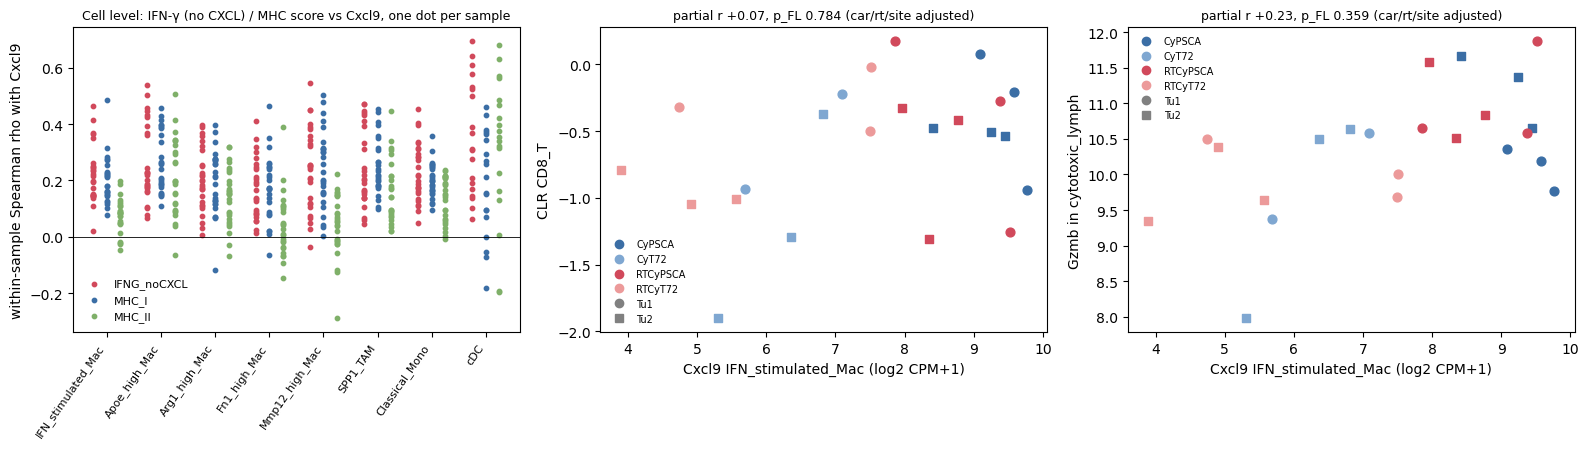

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
d = WR[(WR.chemokine == "Cxcl9")]
for i, st in enumerate(STATES):
    for j, k in enumerate(SCORES):
        v = d[(d.state == st) & (d.score == k)].rho
        ax.scatter(np.full(len(v), i + (j - 1) * 0.25), v, s=10, color=["#d1495b", "#3b6ea5", "#7fb069"][j],
                   label=k if i == 0 else None)
ax.axhline(0, color="k", lw=.6); ax.set_xticks(range(len(STATES)))
ax.set_xticklabels(STATES, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("within-sample Spearman rho with Cxcl9"); ax.legend(fontsize=8, frameon=False)
ax.set_title("Cell level: IFN-γ (no CXCL) / MHC score vs Cxcl9, one dot per sample", fontsize=9)
for ax, (pn, on) in zip(axes[1:], [("Cxcl9 IFN_stimulated_Mac", "CLR CD8_T"),
                                    ("Cxcl9 IFN_stimulated_Mac", "Gzmb in cytotoxic_lymph")]):
    x, y = PRED[pn], OUTC[on]
    smp = [s for s in TREATED if s in x.index and s in y.index]
    for s in smp:
        a = design.loc[s, "arm"]
        ax.scatter(x[s], y[s], s=40, marker="o" if design.loc[s, "site"] == 1 else "s",
                   color={"CyPSCA": "#3b6ea5", "CyT72": "#7fa7d1", "RTCyPSCA": "#d1495b", "RTCyT72": "#ec9a9a"}[a])
    r = CYT[(CYT.predictor == pn) & (CYT.outcome == on)]
    ax.set_xlabel(pn + " (log2 CPM+1)"); ax.set_ylabel(on)
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c_, label=a_) for a_, c_ in
                       {"CyPSCA": "#3b6ea5", "CyT72": "#7fa7d1", "RTCyPSCA": "#d1495b", "RTCyT72": "#ec9a9a"}.items()]
              + [Line2D([], [], marker="o", ls="", color="0.5", label="Tu1"),
                 Line2D([], [], marker="s", ls="", color="0.5", label="Tu2")], fontsize=7, frameon=False)
    ax.set_title(f"partial r {r.partial_r.iloc[0]:+.2f}, p_FL {r.p_FL.iloc[0]:.3f} (car/rt/site adjusted)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG/"04b_ifn_cxcl9_cytotoxic.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Summary

In [11]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print("\n[receptor map — measurable receptor x target (>= 5% positive, >= 8 usable treated samples)]")
print("   ", ", ".join(f"{r.receptor}@{r.target} {r.pct_pos_treated:.0f}%" for _, r in RMAP[RMAP.measurable].iterrows()))
print("    NOT measurable:", ", ".join(f"{r.receptor}@{r.target}" for _, r in RMAP[~RMAP.measurable].iterrows()))
rx = RECX[(RECX.p_main < 0.10) & (RECX.agree == True)] if "p_main" in RECX else pd.DataFrame()
print(f"\n[receptor-positive fraction changes, sign-agree p<0.10] "
      f"{[f'{r.effect}:{r.receptor}@{r.target}({r.main:+.2f})' for _, r in rx.iterrows()] or 'none'}")
print(f"\n[Q3 ligand -> population, treated n~{n_}, MDE |partial r| ~{r_mde:.2f}]")
top = ASSOC[ASSOC.q_BH < 0.10]
print(f"    q<0.10: {[f'{r.ligand}@{r.source}->{r.target} [{r.abundance}] r={r.partial_r:+.2f}' for _, r in top.iterrows()] or 'none'}")
nom = ASSOC[ASSOC.p_FL < 0.05]
print(f"    nominal p<0.05 ({len(nom)} of {len(ASSOC)}; ~{0.05*len(ASSOC):.0f} expected by chance)")
print("\n[Q4a IFN-γ (no CXCL) vs Cxcl9/10 — within-sample mean rho | across-sample partial r]")
for _, r in Q4[Q4.score == "IFNG_noCXCL"].iterrows():
    print(f"    {r.state:<20s} {r.chemokine:<7s} within {r.mean_rho:+.2f} ({100*r.frac_pos:.0f}% of {int(r.n_samples) if pd.notna(r.n_samples) else 0} samples >0, "
          f"p={r.p_t:.2g}) | across {r.partial_r:+.2f} (p_FL {r.p_FL:.3f})")
print("\n[Q4b Cxcl9/10 vs cytotoxic lymphocytes, p_FL < 0.05]")
for _, r in CYT[CYT.p_FL < 0.05].iterrows():
    print(f"    {r.predictor:<34s} -> {r.outcome:<32s} partial r {r.partial_r:+.2f}  p_FL {r.p_FL:.3f}  q {r.q_BH:.3f}")
print("\n[SPP1-high vs IFN-stimulated macrophages, chemokines at within-panel q<0.05]")
for c_, d in SDE[(SDE.panel != "other") & (SDE.panel_padj < 0.05)].groupby("comparison"):
    print(f"    {c_}: " + ", ".join(f"{r.gene} {r.log2FoldChange:+.1f}" for _, r in d.sort_values('log2FoldChange').iterrows()))
gp = GAPX[(GAPX.p_main < 0.10) & (GAPX.agree == True)] if "p_main" in GAPX else pd.DataFrame()
print(f"[SPP1-vs-IFN gap moving with treatment, sign-agree p<0.10] "
      f"{[f'{r.effect}:{r.gene}({r.main:+.2f})' for _, r in gp.iterrows()] or 'none'}")
print("\n[axis table — inferred chemotactic potential counts]")
print(AX.inferred_chemotactic_potential.value_counts().to_string())
print("\n  Wording rule: 'association with composition', never 'recruitment'. Migration is not measured.")
print(f"\n[files] {OUT}: chem_*.csv, chemokine_axis_table_sc.csv | [figure] 04b_ifn_cxcl9_cytotoxic.png")
print("=" * 100)

SUMMARY — report these back

[receptor map — measurable receptor x target (>= 5% positive, >= 8 usable treated samples)]
    Cxcr3@CD8_T 27%, Cxcr3@NK 6%, Ccr5@NK 84%, Ccr5@CD8_T 56%, Ccr5@M1_like_Mac 93%, Ccr5@Classical_Mono 86%, Ccr2@Classical_Mono 84%, Ccr2@Intermediate_Mac 91%, Ccr2@NK 84%, Cxcr2@N1_like_Neu 56%, Cxcr2@N2_like_Neu 16%, Cxcr6@CD8_T 42%, Cxcr4@CD8_T 43%, Cxcr4@NK 21%, Cxcr4@M2_like_Mac 50%, Cxcr4@Classical_Mono 35%, Ackr3@Fibroblast 67%, Ackr3@Endothelial 20%
    NOT measurable: Cxcr3@Treg, Ccr4@NKT, Ccr4@CD4_T, Ccr4@Treg, Cxcr6@NKT, Cxcr6@CD4_T, Xcr1@cDC

[receptor-positive fraction changes, sign-agree p<0.10] ['direct RT:Cxcr3@CD8_T(+0.13)', 'direct RT:Ccr5@CD8_T(+0.22)', 'PSCA:Ccr2@Classical_Mono(-0.09)', 'PSCA:Ccr2@Intermediate_Mac(-0.05)', 'PSCA:Ccr2@NK(-0.09)', 'PSCA:Cxcr6@CD8_T(-0.18)']

[Q3 ligand -> population, treated n~23, MDE |partial r| ~0.59]
    q<0.10: ['Cxcl1@M2_like_Mac->N1_like_Neu [CLR] r=+0.63', 'Cxcl1@M2_like_Mac->N1_like_Neu [receptor+ log-odds